---
title: "Figures: The Ramsey/Cass-Koopmans (RCK) Model"
execute:
  depends_on_env: [IC_EXEC_ENV]
---

<!-- Generated from RamseyCassKoopmans_SST.ipynb by code/notebook_math.py. Don't edit this notebook: edit RamseyCassKoopmans_SST.ipynb, where the math is written with the book's macros, and run the script. -->
Run this notebook in your browser, with nothing to install, in [JupyterLite](https://intertemporal-choice.github.io/lite/notebooks/index.html?path=RamseyCassKoopmans.ipynb); or open it in [Colab](https://colab.research.google.com/github/intertemporal-choice/intertemporal-choice.github.io/blob/main/content/growth/RamseyCassKoopmans/RamseyCassKoopmans.ipynb) or [Binder](https://mybinder.org/v2/gh/intertemporal-choice/intertemporal-choice.github.io/main?labpath=content/growth/RamseyCassKoopmans/RamseyCassKoopmans.ipynb).

In [the RCK model](https://intertemporal-choice.github.io/content/growth/ramseycasskoopmans), capital $k$ and consumption $c$ are measured per efficiency unit of labor, output is $k^{\alpha}$, population grows at the rate $\ell\varXi$ (the log of the population's growth factor $\varXi$, with $\ell$ the natural log) and labor productivity at the rate $\mathrm{g}$, capital depreciates at the rate $\delta$, and the planner has CRRA utility with relative risk aversion $\varrho$ and time preference rate $\vartheta$. Capital and consumption move according to

$$
\dot{k} = k^{\alpha} - c - (\ell\varXi+\mathrm{g}+\delta)k, \qquad \frac{\dot{c}}{c} = \varrho^{-1}\left(\alpha k^{\alpha-1} - \vartheta - \ell\varXi - \delta - \varrho\mathrm{g}\right).
$$

Consumption stops changing at the steady state $\bar{k}$, where $\alpha\bar{k}^{\alpha-1} = \vartheta+\ell\varXi+\delta+\varrho\mathrm{g}$, and steady-state consumption is highest at the golden rule $\bar{\bar{k}}$, where $\alpha\bar{\bar{k}}^{\alpha-1} = \ell\varXi+\mathrm{g}+\delta$. The notebook draws these loci, finds the saddle path by time elimination, the method of the chapter's appendix, and follows the paths that start above and below it.

In [ ]:
# Run anywhere: install the book's package (it brings numpy, scipy and matplotlib) if it
# is missing. Inside the book's own environment this does nothing.
try:
    import intertemporal_choice
except ImportError:
    import importlib.util, sys
    if importlib.util.find_spec("pip"):
        %pip install -q git+https://github.com/intertemporal-choice/intertemporal-choice.github.io
    else:  # a Python without pip, as uv makes: install with uv, or say what to do
        !uv pip install -q --python {sys.executable} git+https://github.com/intertemporal-choice/intertemporal-choice.github.io || echo "Neither pip nor uv can install the book's package here: choose a kernel whose Python has pip, or the course's own environment."

In [ ]:
from dataclasses import dataclass, replace

import numpy as np
from scipy.integrate import solve_ivp

In [ ]:
import matplotlib.pyplot as plt

from intertemporal_choice import notation, ramsey, style

style.use_book_style()

## The economy

`Economy` holds the parameters: $\varrho = 2$, $\alpha = 0.3$, $\vartheta = 0.02$, $\ell\varXi = 0.01$, $\delta = 0.08$ and $\mathrm{g} = 0.03$. `replace(e, phi=0.06)` is the same economy with faster productivity growth. The planner's objective is finite only if $\vartheta > (1-\varrho)\mathrm{g}$; here $\vartheta - (1-\varrho)\mathrm{g} = 0.05$.

In [ ]:
@dataclass(frozen=True)
class Economy:
    rho: float = 2.0     # relative risk aversion
    alpha: float = 0.3   # capital's share of output
    theta: float = 0.02  # time preference rate
    xi: float = 0.01     # population growth rate
    delta: float = 0.08  # depreciation rate
    phi: float = 0.03    # labor productivity growth rate

    @property
    def dilution(self):  # capital per efficiency unit shrinks at this rate when none is added
        return self.xi + self.phi + self.delta


def kdot(e, k, c):
    return k**e.alpha - c - e.dilution * k


def cdot(e, k, c):
    return c * (e.alpha * k ** (e.alpha - 1) - e.theta - e.xi - e.delta - e.rho * e.phi) / e.rho


def kdot_zero(e, k):
    """The kdot = 0 locus: the consumption that keeps k where it is."""
    return k**e.alpha - e.dilution * k


def steady_state(e):
    """(k, c) where neither moves: the cdot/c = 0 line meets the kdot = 0 locus."""
    k = (e.alpha / (e.theta + e.xi + e.delta + e.rho * e.phi)) ** (1 / (1 - e.alpha))
    return k, kdot_zero(e, k)


def golden_rule(e):
    """The k at the top of the kdot = 0 locus, where steady-state consumption is highest."""
    return (e.alpha / e.dilution) ** (1 / (1 - e.alpha))

## The saddle path, by time elimination

The transition has, in general, no analytical solution, so it is computed. The most straightforward method for perfect-foresight models of this kind is "time elimination" ([Mulligan and Sala-i-Martin, 1993](https://doi.org/10.2307/2118407)). Along any path, $dc/dk = \dot{c}/\dot{k}$, so the two equations above give a differential equation in $k$ alone:

$$
\frac{dc}{dk} = \frac{\varrho^{-1}\left(\alpha k^{\alpha-1} - \vartheta - \ell\varXi - \delta - \varrho\mathrm{g}\right)c}{k^{\alpha} - c - (\ell\varXi+\mathrm{g}+\delta)k}.
$$

Its solution along the saddle path is consumption as a function of capital, $\mathrm{c}(k)$. At the steady state both $\dot{c}$ and $\dot{k}$ are zero, so the right-hand side is $0/0$, and the solution can't start there. It is solved twice instead, outward from the steady state on each side, starting a small step away along the saddle path's slope there: once down toward $k=0$, and once up to a large $k$. That slope comes from the system linearized at the steady state: it is the direction of the eigenvector with the negative eigenvalue, the one direction from which the economy converges. Within that small step of the steady state, the consumption function is the straight line along the slope. Judd's *Numerical Methods in Economics* (1998) covers numerical methods for saddle paths more generally.

In [ ]:
def saddle_slope(e):
    """dc/dk along the saddle path at the steady state."""
    k, c = steady_state(e)
    jacobian = np.array([
        [e.alpha * k ** (e.alpha - 1) - e.dilution, -1.0],               # d kdot/dk, d kdot/dc
        [c * e.alpha * (e.alpha - 1) * k ** (e.alpha - 2) / e.rho, 0.0],  # d cdot/dk, d cdot/dc
    ])
    values, vectors = np.linalg.eig(jacobian)
    stable = vectors[:, np.argmin(values)]
    return stable[1] / stable[0]


def saddle_path(e, k_low, k_high):
    """The saddle path's consumption as a function of k on [k_low, k_high]."""
    k_ss, c_ss = steady_state(e)
    slope = saddle_slope(e)
    step = 1e-5 * k_ss
    branches = []
    for end, side in ((k_low, -1), (k_high, 1)):
        start = k_ss + side * step
        branches.append(solve_ivp(lambda k, c: cdot(e, k, c) / kdot(e, k, c), (start, end), [c_ss + slope * side * step],
                                  rtol=1e-10, atol=1e-12, dense_output=True).sol)
    below, above = branches

    def c(k):
        k = np.asarray(k, float)
        near = c_ss + slope * (k - k_ss)  # within a step of the steady state, the straight line between the branches
        return np.where(k < k_ss - step, below(np.minimum(k, k_ss - step))[0],
                        np.where(k > k_ss + step, above(np.maximum(k, k_ss + step))[0], near))

    return c

## Paths off the saddle path

Starting from the same $k_{0}$ with consumption above the saddle path, the economy eats its capital: $k$ reaches zero in finite time. Starting below it, the economy accumulates capital past the golden rule. `path` follows the two differential equations forward in time until $k$ nearly reaches zero or passes `k_max`.

In [ ]:
def path(e, k0, c0, k_max, T=400):
    """The (k, c) path from (k0, c0) until time T, or until k nearly reaches zero or passes k_max."""
    def exhausted(t, y):
        return y[0] - 0.01
    def past(t, y):
        return y[0] - k_max
    exhausted.terminal = past.terminal = True
    solution = solve_ivp(lambda t, y: [kdot(e, *y), cdot(e, *y)], (0, T), [k0, c0], events=[exhausted, past],
                         rtol=1e-9, max_step=0.5)
    return solution.y

## The loci

The $\dot{k}=0$ locus rises to its peak at the golden rule and falls after it; the $\dot{c}/c=0$ line stands at the steady state, to the left of the peak because $\vartheta > (1-\varrho)\mathrm{g}$. Faster productivity growth ($\mathrm{g} = 0.06$ rather than 0.03) lowers both: each efficiency unit of labor needs more investment just to keep its capital, and the planner, who wants consumption to grow faster, holds less capital in the steady state.

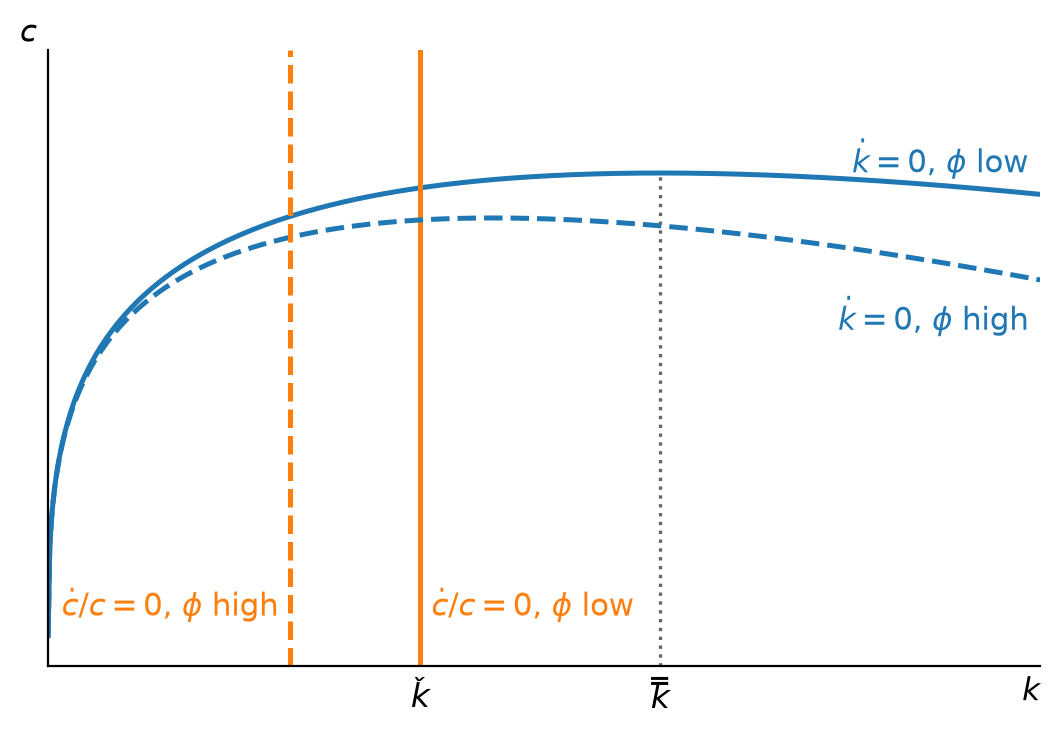

In [ ]:
e = Economy()
fast = replace(e, phi=0.06)
k = np.linspace(1e-4, 6, 600)
fig, ax = plt.subplots()
ramsey.draw_loci(ax, k, {notation.tex(r"$\PtyGroRte$ low"): (kdot_zero(e, k), steady_state(e)[0]),
                         notation.tex(r"$\PtyGroRte$ high"): (kdot_zero(fast, k), steady_state(fast)[0])},
                 golden=golden_rule(e))
style.save(fig, "RamseySSPlot")

## The transition

From $k_{0} = 0.5$, the saddle path's consumption leads to the steady state. Ten percent more consumption leads to the exhaustion of capital, and ten percent less to too much of it.

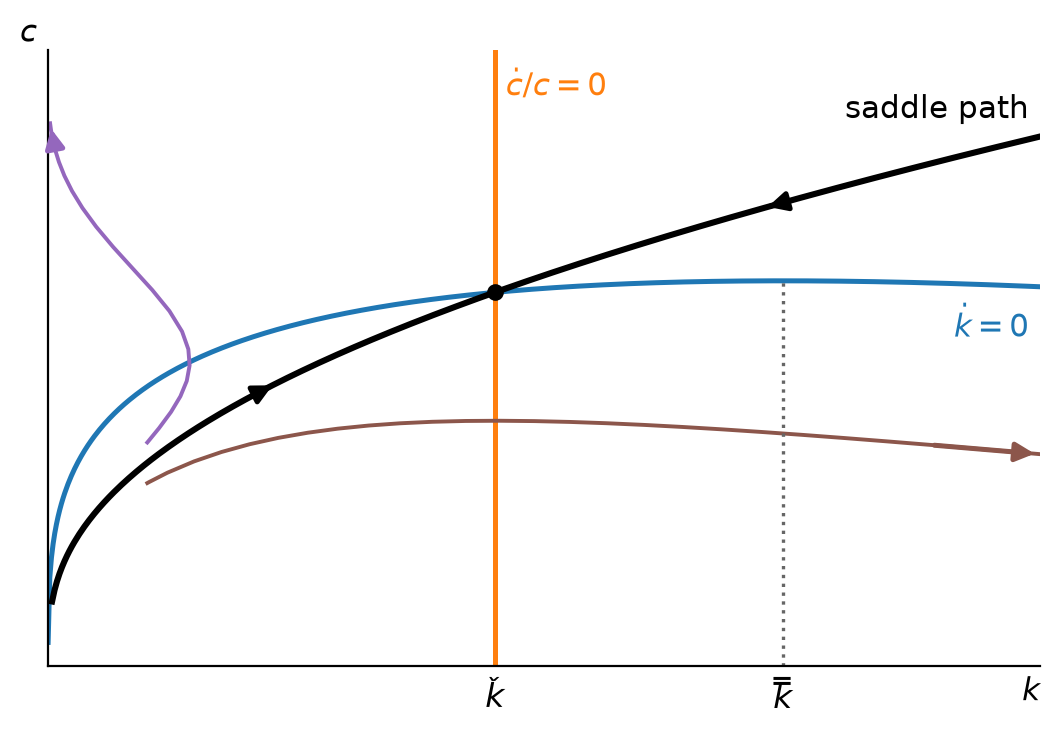

In [ ]:
k_ss, c_ss = steady_state(e)
k = np.linspace(1e-4, 5, 600)
saddle = saddle_path(e, 0.02, 5)
k_saddle = np.linspace(0.02, 5, 400)
k0 = 0.5
above, below = path(e, k0, 1.1 * saddle(k0), k_max=5), path(e, k0, 0.9 * saddle(k0), k_max=5)
fig, ax = plt.subplots()
ramsey.draw_saddle(ax, k, kdot_zero(e, k), (k_ss, c_ss), (k_saddle, saddle(k_saddle)), [above, below],
                   golden=golden_rule(e))
style.save(fig, "RamseySaddlePlot")

## Checks

The numbers above: the steady state, the golden rule, and where each path goes.

In [ ]:
k_ss, c_ss = steady_state(e)
assert round(k_ss, 3) == 2.251 and round(c_ss, 3) == 1.005 and round(golden_rule(e), 2) == 3.70
excess = e.theta - (1 - e.rho) * e.phi  # the objective is finite only if this is positive
assert np.isclose(excess, 0.05)
# f'(k_ss) - f'(k_gold) = theta - (1 - rho) phi, so the steady state is below the golden rule exactly when it is positive.
fprime = lambda e, k: e.alpha * k ** (e.alpha - 1)
assert np.isclose(fprime(e, k_ss) - fprime(e, golden_rule(e)), excess) and k_ss < golden_rule(e)
# Faster growth lowers the steady state and the kdot = 0 locus.
assert steady_state(fast)[0] < k_ss and np.all(kdot_zero(fast, k_saddle) < kdot_zero(e, k_saddle))
# The saddle path passes through the steady state, rises with k, and solves the equations: started on
# it, the economy comes within a thousandth of the steady state (before the smallest numerical error,
# which the equations magnify, takes it away again).
assert np.isclose(saddle(k_ss), c_ss) and np.all(np.diff(saddle(k_saddle)) > 0)
k_on, c_on = path(e, k0, saddle(k0), k_max=5)
assert np.min(np.hypot(k_on / k_ss - 1, c_on / c_ss - 1)) < 1e-3
# Above it, capital runs out; below it, capital passes the golden rule.
assert above[0, -1] < 0.02 and below[0, -1] >= 5 > golden_rule(e)
# The chapter's condition for the steady state to rise with alpha, at these parameters: the left side
# is 1.76 and the right 0.097.
assert round(e.alpha / (e.theta + e.xi + e.delta + e.rho * e.phi), 2) == 1.76 and round(np.exp(-(1 - e.alpha) / e.alpha), 3) == 0.097